# GIS-Based Analysis of Local Parks in Cukurova District

## <span style="color: goldenrod;">Abstract</span>
The main standards regarding the size of local park areas, population density, and service areas were defined. Service areas for each local park were evaluated and mapped using GIS-based network analysis.  

**Key Findings:**  
- 79% of the study area consists of residential zones, while local parks (34 units) cover only 3%.  
- Accessibility to parks reaches 65% within a 500-meter distance but drops to 30% when population density is considered.  
- The spatial distribution of parks is unbalanced, and suggestions were made to improve the situation.  

----------------------

## <span style="color: goldenrod;">Introduction</span>
Urban green spaces, including parks and natural areas, significantly impact quality of life by providing environmental and recreational benefits.  
With increasing urban density, equitable access to green spaces has become a major challenge in urban planning.  

**Key Concept:**  
Accessibility is the proximity or ease of access to parks, influenced by spatial distribution and population density.

----------------------

## <span style="color: goldenrod;">Modeling Accessibility to Urban Green Spaces</span>
### <span style="color: maroon;">Methods:</span>
1. **Euclidean Buffer:**  
   - Simple but inaccurate.  
   - Assumes straight-line movement and ignores real pathways.  

   <br>

2. **Network Analysis:**  
   - Considers real-world routes (streets, pathways, intersections).  
   - Tool used: ArcGIS Network Analyst.

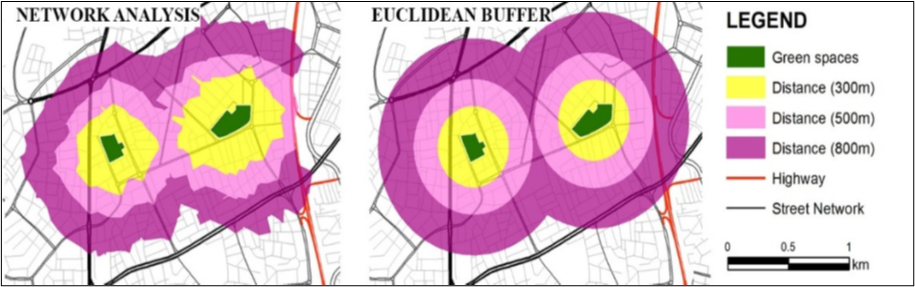 
---

----------------------

## <span style="color: goldenrod;">Study Area and Data</span>
### <span style="color: maroon;">Study Area:</span>  
Cukurova District in Adana, Turkey:  
- **Area:** 4,283 hectares.  
- **Population:** 339,159 (2014).  
- **Public Green Spaces:** 1.8 m² per person (less than the national standard of 10 m²).  

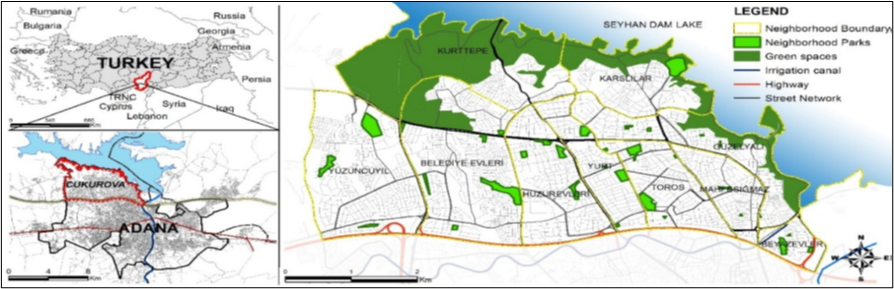

### <span style="color: maroon;">Data Used:</span>
- **Local Park Locations:** Field studies, aerial images, and urban maps.  
- **Street Network:** Including pedestrian paths, overpasses, and underpasses.  
- **Population Data:** From the Turkish Statistical Institute (2014). 

----------------------

## <span style="color: goldenrod;">Methodology</span>
### <span style="color: maroon;">Steps:</span>
1. Locate local parks.  
2. Define accessibility standards.  
3. Evaluate quantitative data and calculate service areas.  
4. Map service areas using network analysis.  
5. Assess accessibility sufficiency.  
6. Propose recommendations.

### <span style="color: maroon;">Accessibility Indicators:</span>
- **Maximum Distance:** 500 meters.  
- **Area Size:** 24,865 m².  
- **Population Density:** Evaluate population's impact on access. 

### <span style="color: maroon;">Formulas:</span>
#### Total Service Area Population (TIAP):
$$
TIAP = \frac{\text{Park Service Area}}{\text{Total Neighborhood Area}} \times \text{Total Population of Neighborhood}
$$

#### Population Density Index (PDI):
$$
PDI = \frac{\text{Park Area}}{\text{TIAP}}
$$

#### Park Service Score (NP Score):
$$
NP \, \text{Score} = \frac{\text{Park Score}}{100} \times 500
$$

----------------------

## <span style="color: goldenrod;">Results</span>
The study analyzed 34 local parks. Key findings include:  
- 79% of the study area is residential, but parks cover only 3%.  
- Only 30% of residents are within 500 meters of a park.  
- High-density neighborhoods like Mahfesığmaz lack adequate parks.  

### <span style="color: maroon;">Comparison of Accessibility Indicators by Neighborhood</span>
<div align="center">

| **ID** | **Neighborhood** | **Area (ha)** | **Parks** | **Park Area (m²)** | **Population** | **Park Score** | **Service Area (m)** |
|--------|------------------|---------------|-----------|--------------------|----------------|----------------|-----------------------|
| 1      | Toros            | 187           | 6         | 86,125            | 61,804         | 30             | 148                   |
| 6      | Mahfesığmaz      | 127           | 2         | 4,885             | 33,965         | 5              | 27                    |
| 10     | Karslılar        | 237           | 1         | 80,592            | 3,785          | 100            | 500                   |

</div>

----------------------

### <span style="color: maroon;">Service Area Map of Parks</span>

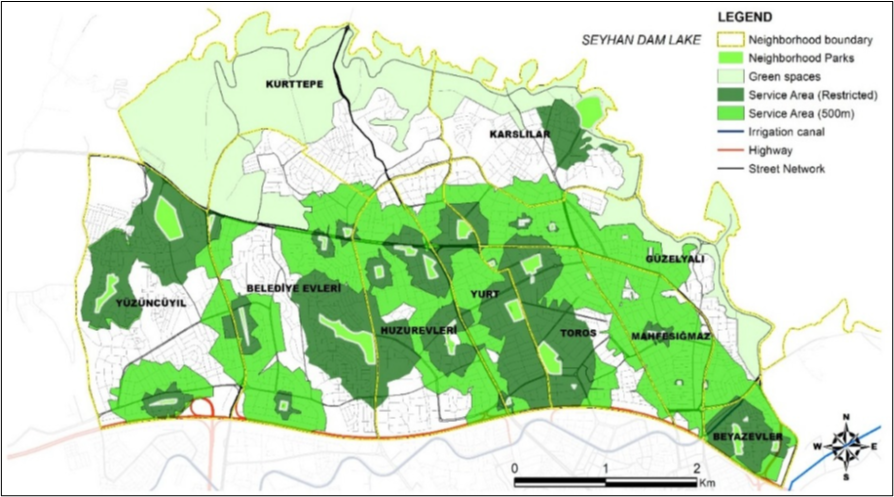

----------------------

## <span style="color: goldenrod;">Conclusion and Recommendations</span>
### <span style="color: maroon;">Conclusion:</span>
- More than half of the population cannot directly access local parks.  
- Park size and population density significantly impact accessibility.  
- Parks near neighborhood boundaries benefit multiple areas.  

<br>

### <span style="color: maroon;">Recommendations:</span>
1. Increase the number of parks in high-density areas.  
2. Design parks with adequate sizes for the population.  
3. Develop comprehensive regulations to ensure equitable access. 

----------------------

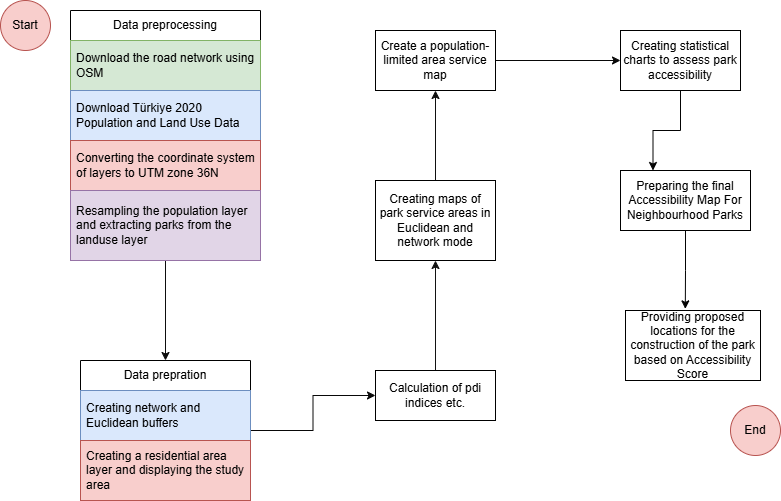

In [2]:
Image(filename = "D:/UNI/Arshad/Term 1/Advanced Spatial Analysis/TA/Project/Untitled Diagram.drawio.png")

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [1]:
import geopandas as gpd
import networkx as nx
import osmnx as ox
import numpy as np
import pandas as pd
import contextily as ctx
import rasterio
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.colors import Normalize
from matplotlib.colorbar import ColorbarBase
from osmnx import graph_from_place, project_graph, plot_graph
from shapely.geometry import Point, Polygon, box, MultiPoint
from tqdm import tqdm
from IPython.display import Image

### Step 1: Prepare the Data

In [3]:
# Load landuse shapefile and filter parks and residential areas
landuse = gpd.read_file(r"D:\UNI\Arshad\Term 1\Advanced Spatial Analysis\TA\Project\Data\LUT\osm_landuse_turkie.shp")
landuse.to_crs(epsg=4326)
landuse

,osm_id,code,fclass,name,geometry
0,4471925,7202,park,Taksim Gezi Parkı,"POLYGON ((28.98571 41.03779, 28.9858 41.03811,..."
1,4515111,7201,forest,Dana Adası,"POLYGON ((33.75695 36.18279, 33.75729 36.1837,..."
2,4516894,7217,scrub,Kameriye Adası,"POLYGON ((28.04475 36.72529, 28.04491 36.72557..."
3,4516975,7201,forest,Göcek Adası,"POLYGON ((28.93355 36.72382, 28.93365 36.72411..."
4,4517001,7217,scrub,Uzun Ada,"POLYGON ((28.00005 36.71853, 28.00006 36.7193,..."
...,...,...,...,...,...
450579,18371458,7208,meadow,None,"POLYGON ((32.91894 38.75494, 32.91899 38.75539..."
450580,18375762,7229,farmland,None,"POLYGON ((32.92301 38.76971, 32.92302 38.76978..."
450581,18353322,7229,farmland,None,"POLYGON ((32.99667 38.81067, 32.99905 38.81162..."
450582,18375824,7229,farmland,None,"POLYGON ((32.93412 38.79954, 32.93428 38.79995..."


----------------------

In [4]:
landuse.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

----------------------

In [5]:
# Define bounding box for the extent
extent = box(35.23839, 37.02366, 35.32448, 37.06963)  # west, south, east, north
landuse_sa = landuse[landuse.intersects(extent)]  # Clip to the extent
landuse_sa = landuse_sa.to_crs(epsg=32636)

# Filter parks and residential areas
residential_areas = landuse_sa[landuse_sa["fclass"] == "residential"]
parks_ = gpd.read_file(r"D:\UNI\Arshad\Term 1\Advanced Spatial Analysis\TA\Project\Data\LUT\Park\osm_park_turkie.shp")
parks_ = parks_.to_crs(epsg=32636)
parks_

,osm_id,code,fclass,name,Shape_Leng,Shape_Area,geometry
0,174082441,7202,park,None,0.012076,3.824450e-06,"POLYGON ((706316.288 4100369.1, 706342.769 410..."
1,180369130,7202,park,Cumhuriyet Parkı,0.006340,2.305100e-06,"POLYGON ((703233.061 4102782.307, 703183.891 4..."
2,180369288,7202,park,Mehmet Akif Ersoy Parkı,0.003113,5.987593e-07,"POLYGON ((701882.555 4102793.894, 701875.079 4..."
3,182657222,7202,park,None,0.003207,4.664903e-07,"POLYGON ((702947.96 4101949.283, 702918.445 41..."
4,182657225,7202,park,None,0.002408,3.816098e-07,"POLYGON ((702954.144 4101819.546, 702935.38 41..."
...,...,...,...,...,...,...,...
150,1303370488,7202,park,Şehit P. Er Tugay Elve Çocuk Parkı,0.001850,2.077545e-07,"POLYGON ((706428.111 4100849.836, 706432.164 4..."
151,1303370489,7202,park,Beyazevler Mahallesi 2 Nolu Çocuk Parkı,0.001427,8.946384e-08,"POLYGON ((706283.005 4100839.523, 706236.542 4..."
152,1303370582,7202,park,Çobandede Parkı,0.010831,7.315143e-06,"POLYGON ((704544.461 4103942.346, 704535.641 4..."
153,1306305081,7202,park,Çınarlı Parkı,0.001646,1.567183e-07,"POLYGON ((705131.238 4101111.851, 705103.863 4..."


----------------------

In [6]:
parks_.crs

<Projected CRS: EPSG:32636>
Name: WGS 84 / UTM zone 36N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 30°E and 36°E, northern hemisphere between equator and 84°N, onshore and offshore. Belarus. Cyprus. Egypt. Ethiopia. Finland. Israel. Jordan. Kenya. Lebanon. Moldova. Norway. Russian Federation. Saudi Arabia. Sudan. Syria. Türkiye (Turkey). Uganda. Ukraine.
- bounds: (30.0, 0.0, 36.0, 84.0)
Coordinate Operation:
- name: UTM zone 36N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

----------------------

In [7]:
# Extract road network from OSM
study_area = "Cukurova, Adana, Turkey"
graph = graph_from_place(study_area, network_type="walk")
graph = project_graph(graph)

In [8]:
nodes, edges = ox.graph_to_gdfs(graph)
edges.to_file(r"D:\UNI\Arshad\Term 1\Advanced Spatial Analysis\TA\Project\Data\WalkT\graph_edges.shp") 
nodes.to_file(r"D:\UNI\Arshad\Term 1\Advanced Spatial Analysis\TA\Project\Data\WalkT\graph_nodes.shp")
edges.crs

<Projected CRS: EPSG:32636>
Name: WGS 84 / UTM zone 36N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 30°E and 36°E, northern hemisphere between equator and 84°N, onshore and offshore. Belarus. Cyprus. Egypt. Ethiopia. Finland. Israel. Jordan. Kenya. Lebanon. Moldova. Norway. Russian Federation. Saudi Arabia. Sudan. Syria. Türkiye (Turkey). Uganda. Ukraine.
- bounds: (30.0, 0.0, 36.0, 84.0)
Coordinate Operation:
- name: UTM zone 36N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

----------------------

In [9]:
# Load population density raster and clip to extent
with rasterio.open(r"D:\UNI\Arshad\Term 1\Advanced Spatial Analysis\TA\Project\Data\PDT\tur_pd_2020_10m_Project.tif") as src:
    population_density = src.read(1)
    affine = src.transform

rows, cols = np.indices(population_density.shape)
x, y = affine * (cols.flatten(), rows.flatten())

population_points = gpd.GeoDataFrame(
    {"density": population_density.flatten()},
    geometry=gpd.points_from_xy(x.flatten(), y.flatten()))

population_points = population_points[population_points["density"] > 0]  # Remove null density
population_points

,density,geometry
17032,7462.094238,POINT (698443.398 4104747.667)
17033,7462.094238,POINT (698453.398 4104747.667)
17034,7462.094238,POINT (698463.398 4104747.667)
17035,7462.094238,POINT (698473.398 4104747.667)
17036,7462.094238,POINT (698483.398 4104747.667)
...,...,...
426384,3771.955566,POINT (698653.398 4099937.667)
426385,3771.955566,POINT (698663.398 4099937.667)
426386,3771.955566,POINT (698673.398 4099937.667)
426387,3771.955566,POINT (698683.398 4099937.667)


----------------------

### Step 2: Create Euclidean and Network Buffers

In [10]:
tqdm.pandas()

def network_buffer(park, graph, distance):
    # Find the nearest nodes to all vertices of the park
    park_vertices = list(park.exterior.coords)
    nearest_nodes = [ox.distance.nearest_nodes(graph, vertex[0], vertex[1]) for vertex in park_vertices]
    reachable_nodes = set()
    
    # Find reachable nodes within the specified distance
    for node in nearest_nodes:
        reachable_nodes.update(nx.single_source_dijkstra_path_length(graph, node, distance, weight="length").keys())
    
    # Create network buffer using reachable coordinates
    reachable_coords = [(graph.nodes[node]["x"], graph.nodes[node]["y"]) for node in reachable_nodes]
    
    # Filter out coordinates that are inside the park polygon
    outside_coords = [coord for coord in reachable_coords if not park.contains(Point(coord))]
    
    if outside_coords:
        # Create a convex hull buffer
        network_buffer = MultiPoint(outside_coords).convex_hull
        network_buffer = network_buffer.difference(park)        
        return network_buffer
    else:
        return None

def create_buffer(parks, graph, distance):
    # Euclidean buffer
    parks['euclidean_buffer'] = parks.geometry.buffer(distance).difference(parks.geometry)
    
    # Apply network_buffer function to each park
    parks['network_buffer'] = parks.geometry.progress_apply(lambda park: network_buffer(park, graph, distance))
    
    return parks

In [11]:
parks_buffer = create_buffer(parks_, graph, 500)
parks_buffer 

100%|████████████████████████████████████████████████████████████████████████████████| 155/155 [02:52<00:00,  1.11s/it]


,osm_id,code,fclass,name,Shape_Leng,Shape_Area,geometry,euclidean_buffer,network_buffer
0,174082441,7202,park,None,0.012076,3.824450e-06,"POLYGON ((706316.288 4100369.1, 706342.769 410...","POLYGON ((705629.247 4100506.567, 705618.133 4...","POLYGON ((706243.938 4100424.704, 706210.844 4..."
1,180369130,7202,park,Cumhuriyet Parkı,0.006340,2.305100e-06,"POLYGON ((703233.061 4102782.307, 703183.891 4...","POLYGON ((703138.899 4102276.718, 703089.979 4...","POLYGON ((703452.119 4102466.166, 703243.847 4..."
2,180369288,7202,park,Mehmet Akif Ersoy Parkı,0.003113,5.987593e-07,"POLYGON ((701882.555 4102793.894, 701875.079 4...","POLYGON ((701365.292 4102711.251, 701350.935 4...","POLYGON ((701958.722 4102368.836, 701709.356 4..."
3,182657222,7202,park,None,0.003207,4.664903e-07,"POLYGON ((702947.96 4101949.283, 702918.445 41...","POLYGON ((703381.585 4101700.347, 703352.07 41...","POLYGON ((702916.42 4101763.463, 702913.988 41..."
4,182657225,7202,park,None,0.002408,3.816098e-07,"POLYGON ((702954.144 4101819.546, 702935.38 41...","POLYGON ((703284.736 4101444.435, 703265.972 4...","POLYGON ((703025.642 4101539.544, 702877.349 4..."
...,...,...,...,...,...,...,...,...,...
150,1303370488,7202,park,Şehit P. Er Tugay Elve Çocuk Parkı,0.001850,2.077545e-07,"POLYGON ((706428.111 4100849.836, 706432.164 4...","POLYGON ((706026.46 4100461.398, 705994.901 41...","POLYGON ((706002.327 4100644.85, 705972.294 41..."
151,1303370489,7202,park,Beyazevler Mahallesi 2 Nolu Çocuk Parkı,0.001427,8.946384e-08,"POLYGON ((706283.005 4100839.523, 706236.542 4...","POLYGON ((706782.552 4100860.802, 706782.228 4...","POLYGON ((706188.325 4100481.212, 706183.135 4..."
152,1303370582,7202,park,Çobandede Parkı,0.010831,7.315143e-06,"POLYGON ((704544.461 4103942.346, 704535.641 4...","POLYGON ((703941.509 4103941.383, 703939.815 4...","POLYGON ((703937.643 4103984.476, 704070.369 4..."
153,1306305081,7202,park,Çınarlı Parkı,0.001646,1.567183e-07,"POLYGON ((705131.238 4101111.851, 705103.863 4...","POLYGON ((705628.474 4101164.35, 705631.23 410...","POLYGON ((704708.706 4101062.887, 704635.932 4..."


----------------------

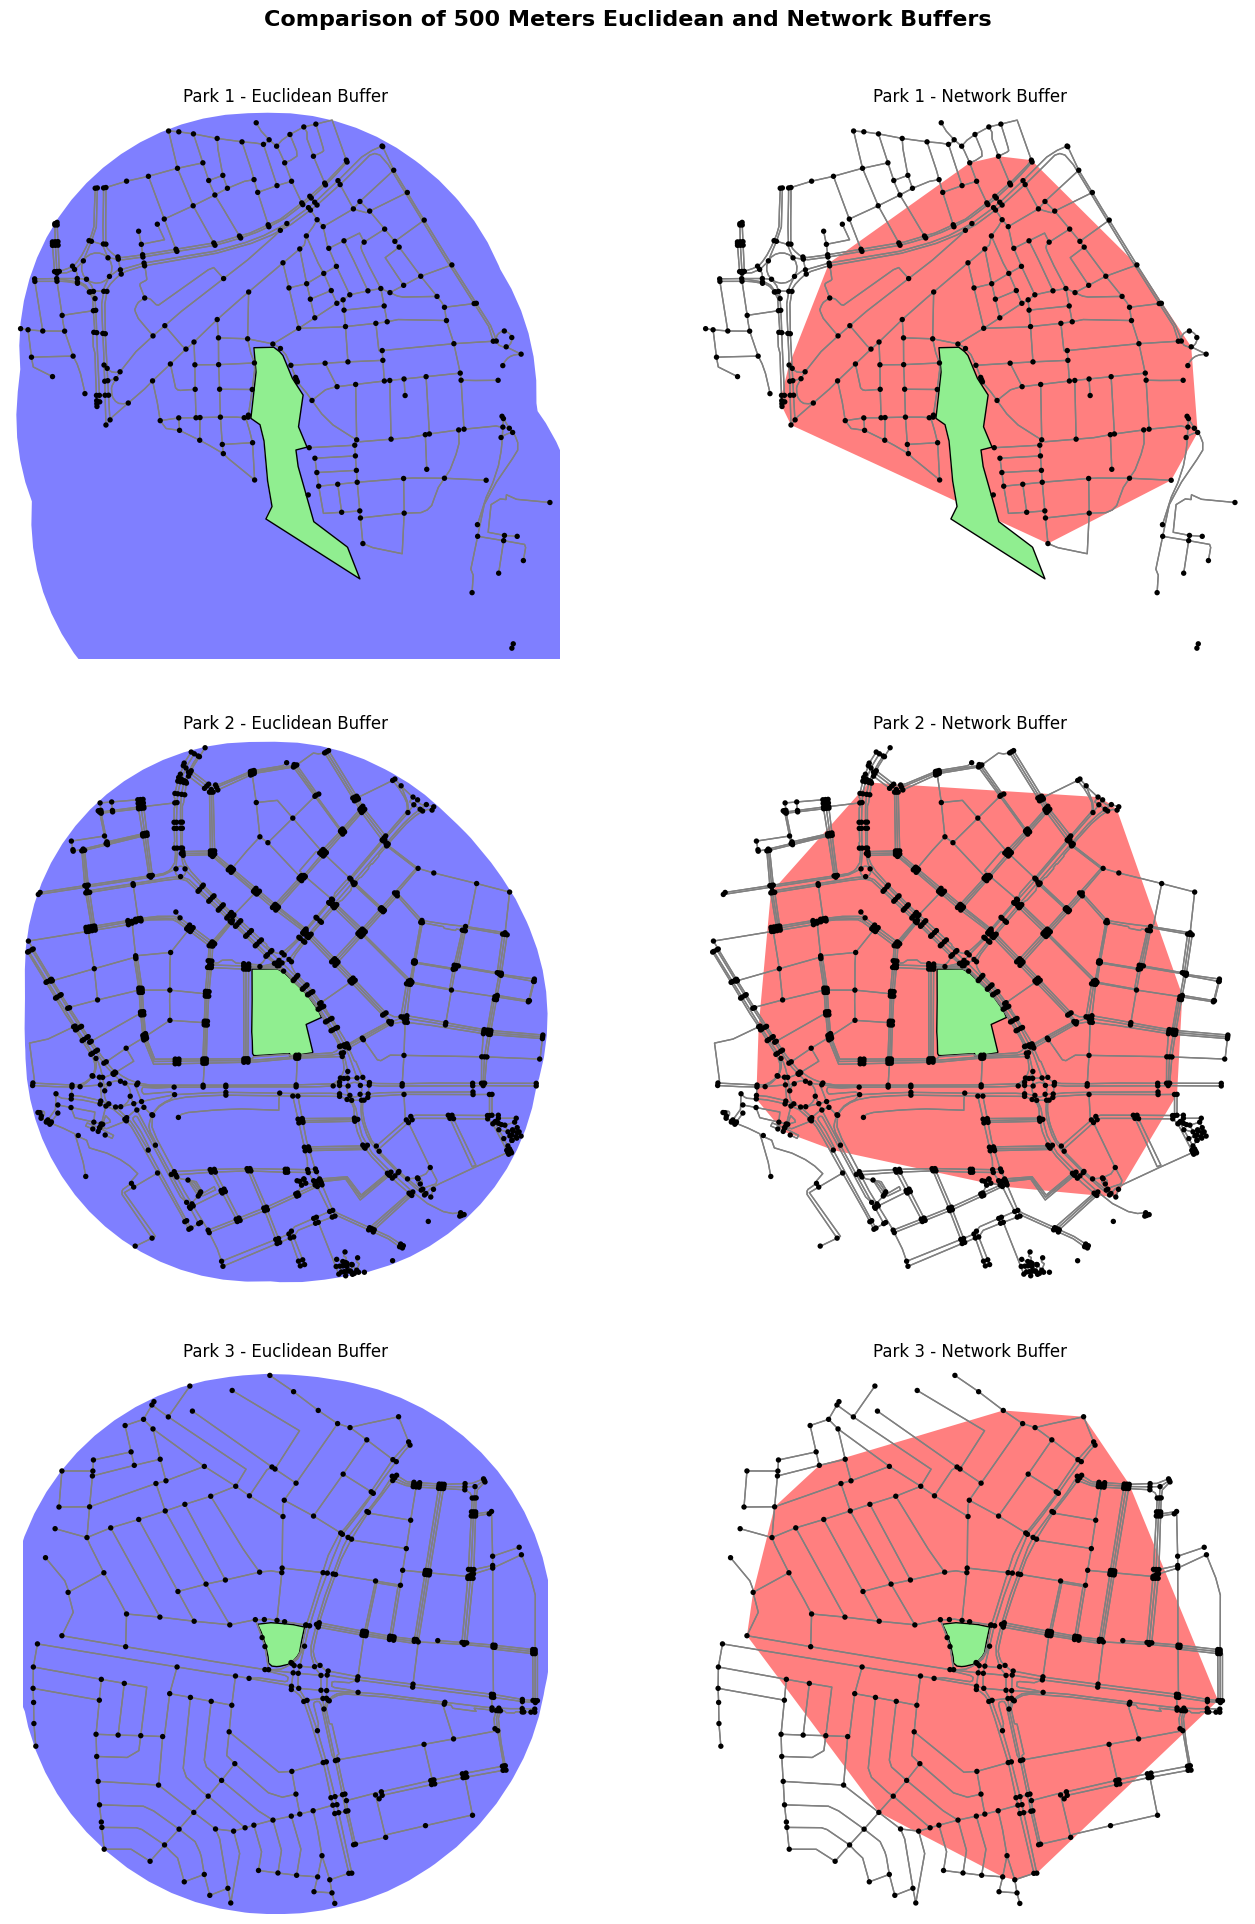

In [12]:
parks = parks_buffer 

def plot_buffers(parks, graph):
    selected_parks = parks.head(3)
    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 20))
    fig.suptitle('Comparison of 500 Meters Euclidean and Network Buffers', fontsize=16, fontweight='bold')
    
    for i, (idx, park) in enumerate(selected_parks.iterrows()):
        # Get the buffers
        euclidean_buffer = park['euclidean_buffer']
        network_buffer = park['network_buffer']
        
        # Get the subgraph for the current park
        subgraph_nodes = list(graph.nodes)
        subgraph_edges = list(graph.edges)
        
        if euclidean_buffer is not None:
            subgraph_nodes = [node for node in graph.nodes if euclidean_buffer.contains(Point(graph.nodes[node]['x'], graph.nodes[node]['y']))]
            subgraph_edges = [edge for edge in graph.edges if euclidean_buffer.contains(Point(graph.nodes[edge[0]]['x'], graph.nodes[edge[0]]['y'])) and euclidean_buffer.contains(Point(graph.nodes[edge[1]]['x'], graph.nodes[edge[1]]['y']))]
        
        subgraph = graph.subgraph(subgraph_nodes)
        
        # Plot Euclidean buffer
        ax = axes[i, 0]
        gpd.GeoSeries([euclidean_buffer]).plot(ax=ax, alpha=0.5, color='blue', label='Euclidean Buffer')
        gpd.GeoSeries([park.geometry]).plot(ax=ax, edgecolor='black', facecolor='lightgreen', label='Park')
        ox.plot_graph(subgraph, ax=ax, show=False, close=False, edge_color='gray', node_color='black')
        ax.set_title(f'Park {i+1} - Euclidean Buffer', fontsize=12)
        
        # Plot Network buffer
        ax = axes[i, 1]
        if network_buffer is not None:
            gpd.GeoSeries([network_buffer]).plot(ax=ax, alpha=0.5, color='red', label='Network Buffer')
        gpd.GeoSeries([park.geometry]).plot(ax=ax, edgecolor='black', facecolor='lightgreen', label='Park')
        ox.plot_graph(subgraph, ax=ax, show=False, close=False, edge_color='gray', node_color='black')
        ax.set_title(f'Park {i+1} - Network Buffer', fontsize=12)

        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(handles, labels)
            
    plt.tight_layout(pad=4.0)
    plt.subplots_adjust(top=0.93)
    plt.show()

plot_buffers(parks_, graph)

----------------------

In [13]:
# Clip the residential areas and roads to the bounding box of parks
minx, miny, maxx, maxy = parks.total_bounds
bounding_box = box(minx, miny, maxx, maxy)
residential_areas_sa = gpd.clip(residential_areas, bounding_box)
edges_sa = gpd.clip(edges, bounding_box)
residential_areas_sa

,osm_id,code,fclass,name,geometry
165016,569640500,7203,residential,None,"POLYGON ((699106.194 4103654.068, 699292.002 4..."
431098,1271212312,7203,residential,None,"POLYGON ((703527.337 4100346.166, 703529.928 4..."
431100,1271212318,7203,residential,None,"POLYGON ((703632.113 4100383.715, 703649.84 41..."
431099,1271212315,7203,residential,None,"POLYGON ((703711.624 4100408.345, 703728.138 4..."
165011,569612044,7203,residential,None,"POLYGON ((705887.126 4101150.815, 705942.34 41..."
430024,1265618393,7203,residential,None,"POLYGON ((704580.135 4102165.216, 704654.374 4..."
430023,1265618392,7203,residential,None,"POLYGON ((704542.108 4102238.693, 704589.686 4..."
430022,1265618391,7203,residential,None,"POLYGON ((704572.115 4102352.83, 704601.255 41..."
430021,1265618390,7203,residential,None,"POLYGON ((704344.896 4102374.013, 704369.031 4..."
430020,1265618389,7203,residential,None,"POLYGON ((704325.639 4102397.129, 704344.896 4..."


----------------------

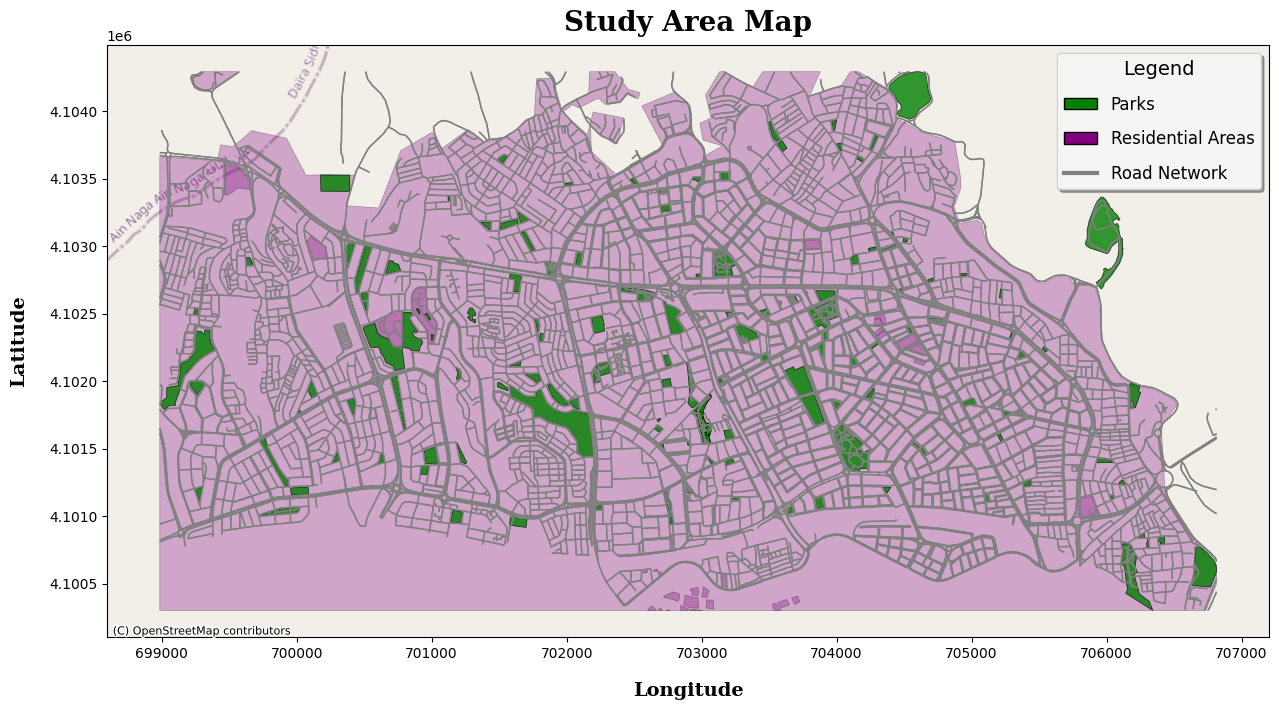

In [14]:
# Create Figure (Study Area Map with Roads)
fig, ax = plt.subplots(figsize=(15, 15))
residential_areas_sa.plot(ax=ax, color='purple', edgecolor='black', linewidth=0.5, alpha=0.3, label='Residential Areas')
parks.plot(ax=ax, color='green', edgecolor='black', linewidth=0.5, alpha=0.8, label='Parks')
edges_sa.plot(ax=ax, linewidth=1, edgecolor='gray', label='Road Network')

# Add basemap for context
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)
ax.set_title('Study Area Map', fontsize=20, fontweight='bold', fontfamily='serif', pad=10)
ax.set_xlabel('Longitude', fontsize=14, fontweight='bold', fontfamily='serif', labelpad=15)
ax.set_ylabel('Latitude', fontsize=14, fontweight='bold', fontfamily='serif', labelpad=15)

# Manually create the legend
legend_elements = [
    Patch(facecolor='green', edgecolor='black', label='Parks'),
    Patch(facecolor='purple', edgecolor='black', label='Residential Areas'),
    plt.Line2D([0], [0], color='gray', lw=3, label='Road Network')]

ax.legend(handles=legend_elements, loc='upper right', fontsize=12, title='Legend', title_fontsize='14', 
          frameon=True, framealpha=0.9, fancybox=True, shadow=True, labelspacing=1)

plt.show()
#plt.savefig("figure2.png")

----------------------

### Step 3: Evaluate Parks Using Equations PDI

In [15]:
def evaluate_parks(parks, population_points):
    results = []
    
    for i, park in parks.iterrows():
        service_area = park["network_buffer"]
        pop_within_area = population_points[population_points.geometry.within(service_area)]
        total_population = pop_within_area["density"].sum()
        park_area = service_area.area
        pdi = total_population / park_area if park_area > 0 else 0
        compliance = park_area >= 24865  # Compliance with minimum size
        results.append({
            "park_index": i,
            "total_population": total_population,
            "park_area": park_area,
            "pdi": pdi,
            "compliant": compliance
        })
    return pd.DataFrame(results)

evaluation_results = evaluate_parks(parks, population_points)
evaluation_results

,park_index,total_population,park_area,pdi,compliant
0,0,5777150.00,459159.739236,12.582005,True
1,1,9154312.00,678482.084225,13.492342,True
2,2,9007954.00,595456.355186,15.127816,True
3,3,3123861.75,140217.647701,22.278663,True
4,4,7131829.00,202421.201704,35.232619,True
...,...,...,...,...,...
150,150,4642176.00,387009.673880,11.994987,True
151,151,5376343.00,449902.857371,11.950009,True
152,152,2504004.50,398664.971707,6.280974,True
153,153,7209783.00,420190.126884,17.158383,True


----------------------

### Step 4: Service Areas Mapping

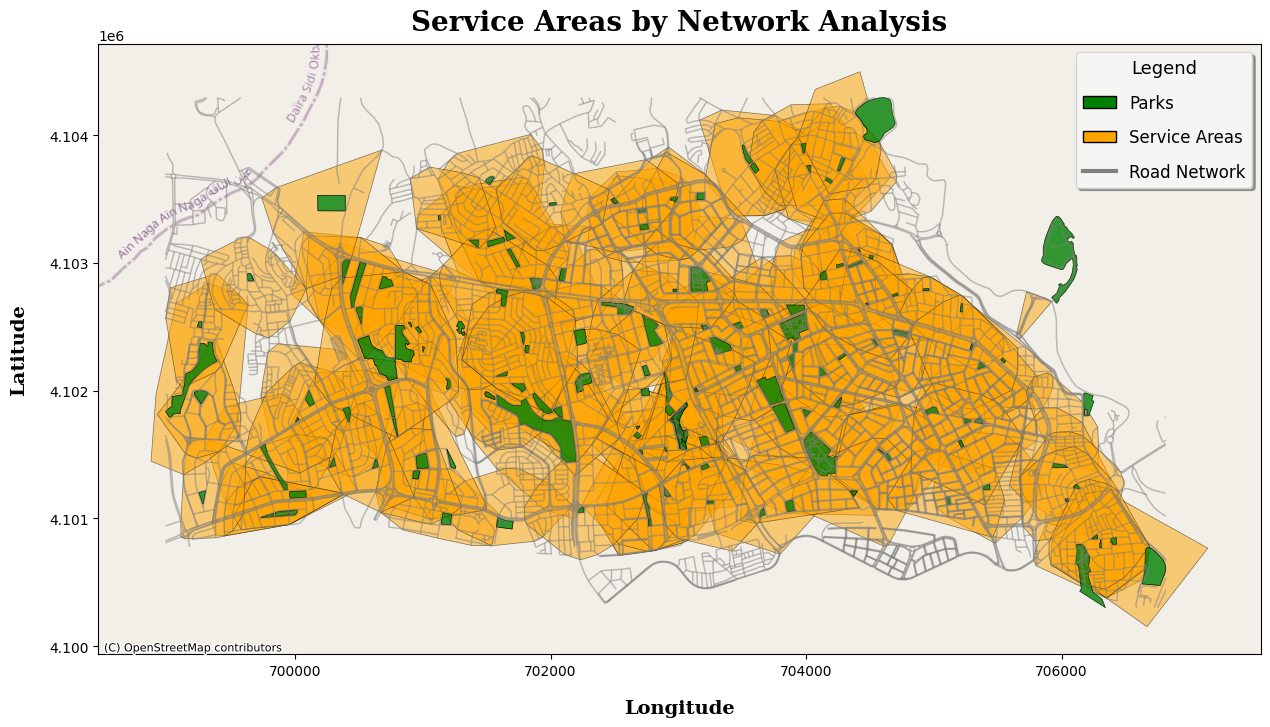

In [16]:
fig, ax = plt.subplots(figsize=(15, 15))
parks["network_buffer"].plot(ax=ax, color='orange', edgecolor='black', linewidth=0.5, alpha=0.5, label='Service Areas (Network Buffer)')
parks.plot(ax=ax, color='green', edgecolor='black', linewidth=0.5, alpha=0.8, label='Parks')
edges_sa.plot(ax=ax, linewidth=1, edgecolor='gray', alpha=0.3, label='Road Network')

# Add basemap for context
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)
ax.set_title('Service Areas by Network Analysis', fontsize=20, fontweight='bold', fontfamily='serif', pad=10)
ax.set_xlabel('Longitude', fontsize=14, fontweight='bold', fontfamily='serif', labelpad=15)
ax.set_ylabel('Latitude', fontsize=14, fontweight='bold', fontfamily='serif', labelpad=15)

# Manually create the legend
legend_elements = [
    Patch(facecolor='green', edgecolor='black', label='Parks'),
    Patch(facecolor='orange', edgecolor='black', label='Service Areas'),
    plt.Line2D([0], [0], color='gray', lw=3, label='Road Network')]

ax.legend(handles=legend_elements, loc='upper right', fontsize=12, title='Legend', title_fontsize='13', 
          frameon=True, framealpha=0.9, fancybox=True, shadow=True, labelspacing=1)

plt.show()
#plt.savefig("figure4_network.png")

----------------------

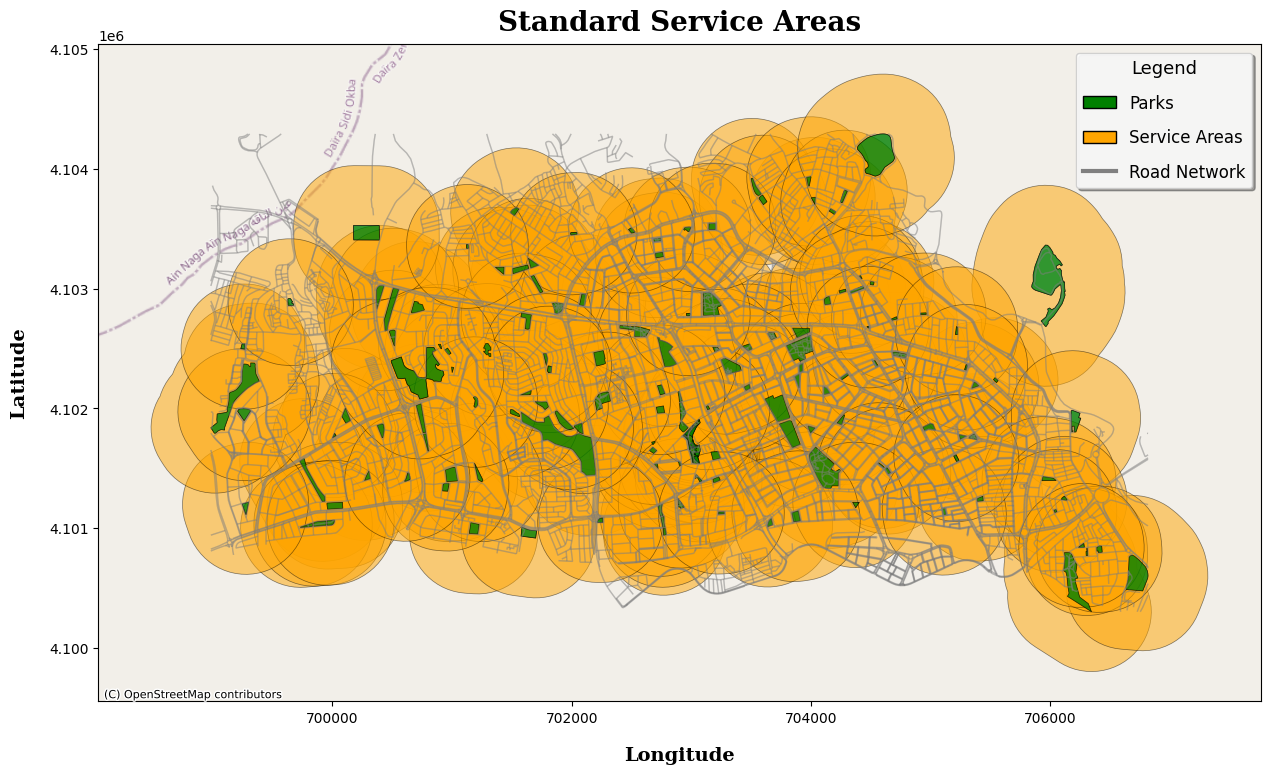

In [17]:
# Additional plot for Euclidean buffer service areas
fig, ax = plt.subplots(figsize=(15, 15))
parks["euclidean_buffer"].plot(ax=ax, color='orange', edgecolor='black', linewidth=0.5, alpha=0.5, label='Service Areas (euclidean Buffer)')
parks.plot(ax=ax, color='green', edgecolor='black', linewidth=0.5, alpha=0.8, label='Parks')
edges_sa.plot(ax=ax, linewidth=1, edgecolor='gray', alpha=0.3, label='Road Network')

# Add basemap for context
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)
ax.set_title('Standard Service Areas', fontsize=20, fontweight='bold', fontfamily='serif', pad=10)
ax.set_xlabel('Longitude', fontsize=14, fontweight='bold', fontfamily='serif', labelpad=15)
ax.set_ylabel('Latitude', fontsize=14, fontweight='bold', fontfamily='serif', labelpad=15)

# Manually create the legend
legend_elements = [
    Patch(facecolor='green', edgecolor='black', label='Parks'),
    Patch(facecolor='orange', edgecolor='black', label='Service Areas'),
    plt.Line2D([0], [0], color='gray', lw=3, label='Road Network')]

ax.legend(handles=legend_elements, loc='upper right', fontsize=12, title='Legend', title_fontsize='13', 
          frameon=True, framealpha=0.9, fancybox=True, shadow=True, labelspacing=1)

plt.show()
#plt.savefig("figure4_euclidean.png")

----------------------

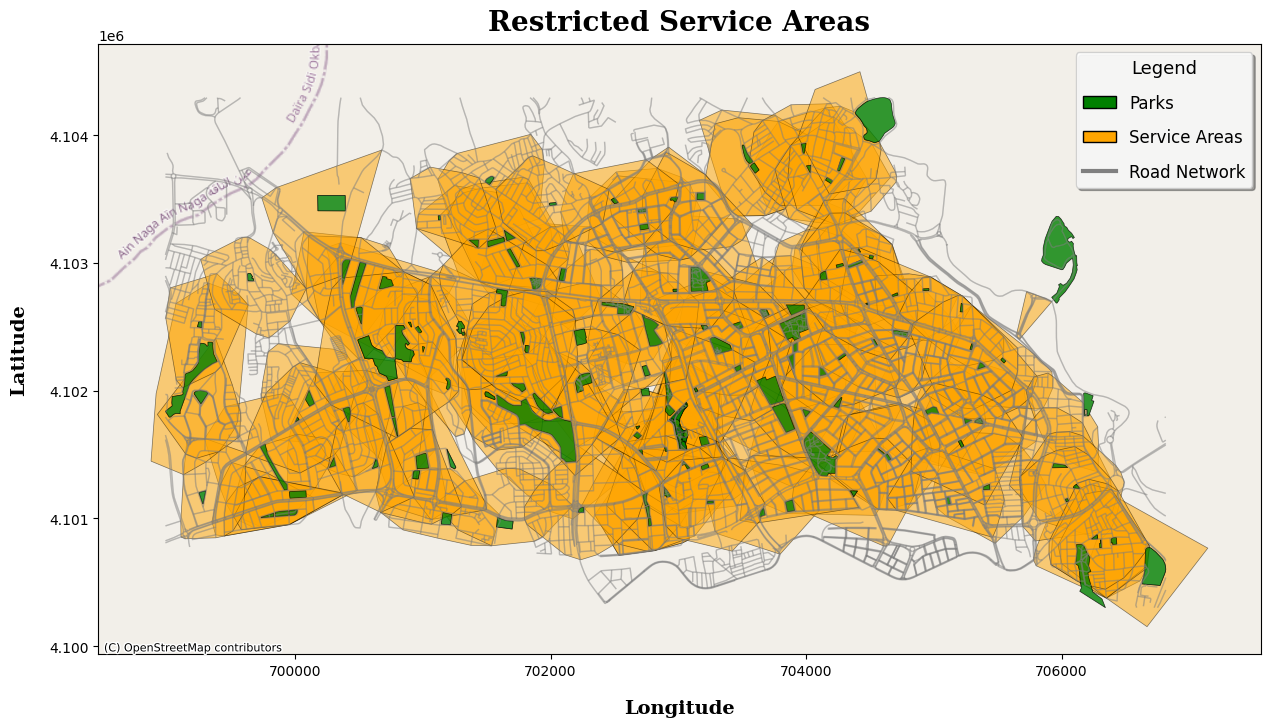

In [18]:
parks["restricted_service_area"] = parks["network_buffer"].where(parks["network_buffer"].intersects(population_points.unary_union))

# Create Figure (Restricted Service Areas)
fig, ax = plt.subplots(figsize=(15, 15))
parks["restricted_service_area"].plot(ax=ax, color="orange", edgecolor='black', linewidth=0.5, alpha=0.5, label="Restricted Service Areas")
parks.plot(ax=ax, color='green', edgecolor='black', linewidth=0.5, alpha=0.8, label='Parks')
edges_sa.plot(ax=ax, linewidth=1, edgecolor='gray', alpha=0.3, label='Road Network')

# Add basemap for context
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)
ax.set_title('Restricted Service Areas', fontsize=20, fontweight='bold', fontfamily='serif', pad=10)
ax.set_xlabel('Longitude', fontsize=14, fontweight='bold', fontfamily='serif', labelpad=15)
ax.set_ylabel('Latitude', fontsize=14, fontweight='bold', fontfamily='serif', labelpad=15)

# Manually create the legend
legend_elements = [
    Patch(facecolor='green', edgecolor='black', label='Parks'),
    Patch(facecolor='orange', edgecolor='black', label='Service Areas'),
    plt.Line2D([0], [0], color='gray', lw=3, label='Road Network')]

ax.legend(handles=legend_elements, loc='upper right', fontsize=12, title='Legend', title_fontsize='13', 
          frameon=True, framealpha=0.9, fancybox=True, shadow=True, labelspacing=1)

plt.show()
#plt.savefig("figure5.png")

----------------------

### Step 5: Create Comparison Graph

In [34]:
neighborhood_comparison = evaluation_results.groupby("park_index").agg({
    "total_population": "sum",
    "park_area": "sum",
    "pdi": "mean"
}).reset_index()

# Normalize the columns 'park_area' and 'pdi' between 0 and 1
neighborhood_comparison["park_area_normalized"] = (neighborhood_comparison["park_area"] - neighborhood_comparison["park_area"].min()) / (neighborhood_comparison["park_area"].max() - neighborhood_comparison["park_area"].min())
neighborhood_comparison["pdi_normalized"] = (neighborhood_comparison["pdi"] - neighborhood_comparison["pdi"].min()) / (neighborhood_comparison["pdi"].max() - neighborhood_comparison["pdi"].min())
neighborhood_comparison["pdi_normalized"] = neighborhood_comparison["pdi_normalized"] * 100
neighborhood_comparison

,park_index,total_population,park_area,pdi,park_area_normalized,pdi_normalized
0,0,5777150.00,459159.739236,12.582005,0.363949,2.638230
1,1,9154312.00,678482.084225,13.492342,0.556734,3.019386
2,2,9007954.00,595456.355186,15.127816,0.483755,3.704156
3,3,3123861.75,140217.647701,22.278663,0.083598,6.698202
4,4,7131829.00,202421.201704,35.232619,0.138276,12.121999
...,...,...,...,...,...,...
150,150,4642176.00,387009.673880,11.994987,0.300529,2.392446
151,151,5376343.00,449902.857371,11.950009,0.355813,2.373614
152,152,2504004.50,398664.971707,6.280974,0.310774,0.000000
153,153,7209783.00,420190.126884,17.158383,0.329695,4.554350


----------------------

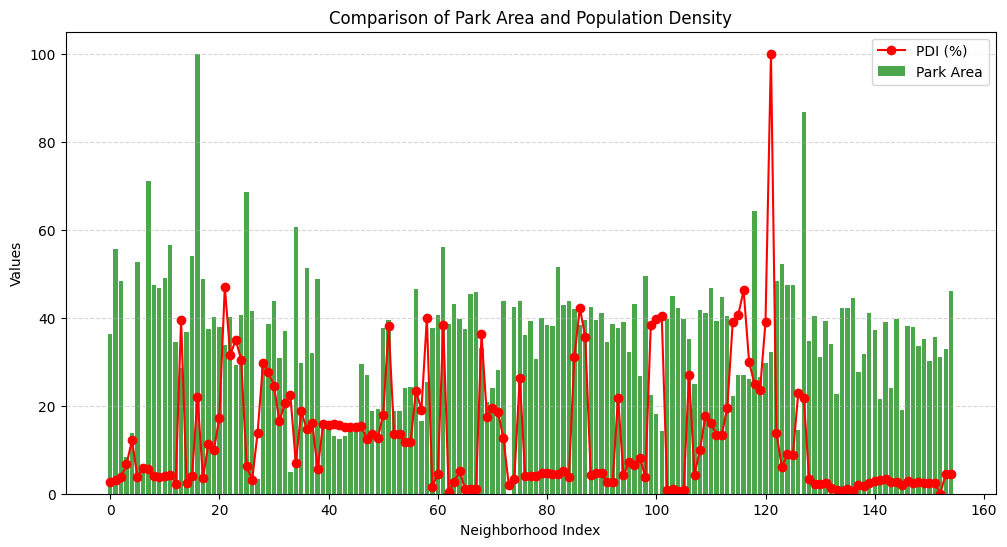

In [35]:
fig6, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(neighborhood_comparison.index, neighborhood_comparison["park_area_normalized"]*100, label="Park Area", color="green", alpha=0.7)
line = ax.plot(neighborhood_comparison.index, neighborhood_comparison["pdi_normalized"], color="red", marker="o", label="PDI (%)")
plt.title("Comparison of Park Area and Population Density")
plt.xlabel("Neighborhood Index")
plt.ylabel("Values")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
#plt.savefig("figure6.png")

----------------------

### Step 6: Summarized Accessibility Statistics

In [29]:
total_parks = len(parks)
total_service_area = parks["network_buffer"].area.sum()
accessible_population = evaluation_results["total_population"].sum()
percent_accessible = 100 - (accessible_population / total_service_area)
percent_accessible

64.16161270296199

----------------------

Text(0.5, 1.0, 'Accessibility Statistics (Population)')

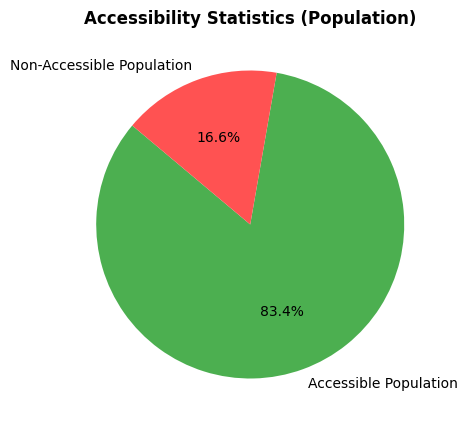

In [30]:
# Pie chart to visualize accessibility statistics
fig7, ax = plt.subplots(figsize=(5, 5))
labels = ["Accessible Population", "Non-Accessible Population"]
sizes = [accessible_population, accessible_population - population_points["density"].sum()]
colors = ["#4CAF50", "#FF5252"]
ax.pie(sizes, labels=labels, autopct="%1.1f%%", startangle=140, colors=colors)
plt.title("Accessibility Statistics (Population)", fontweight='bold')
#plt.savefig("figure7.png")

----------------------

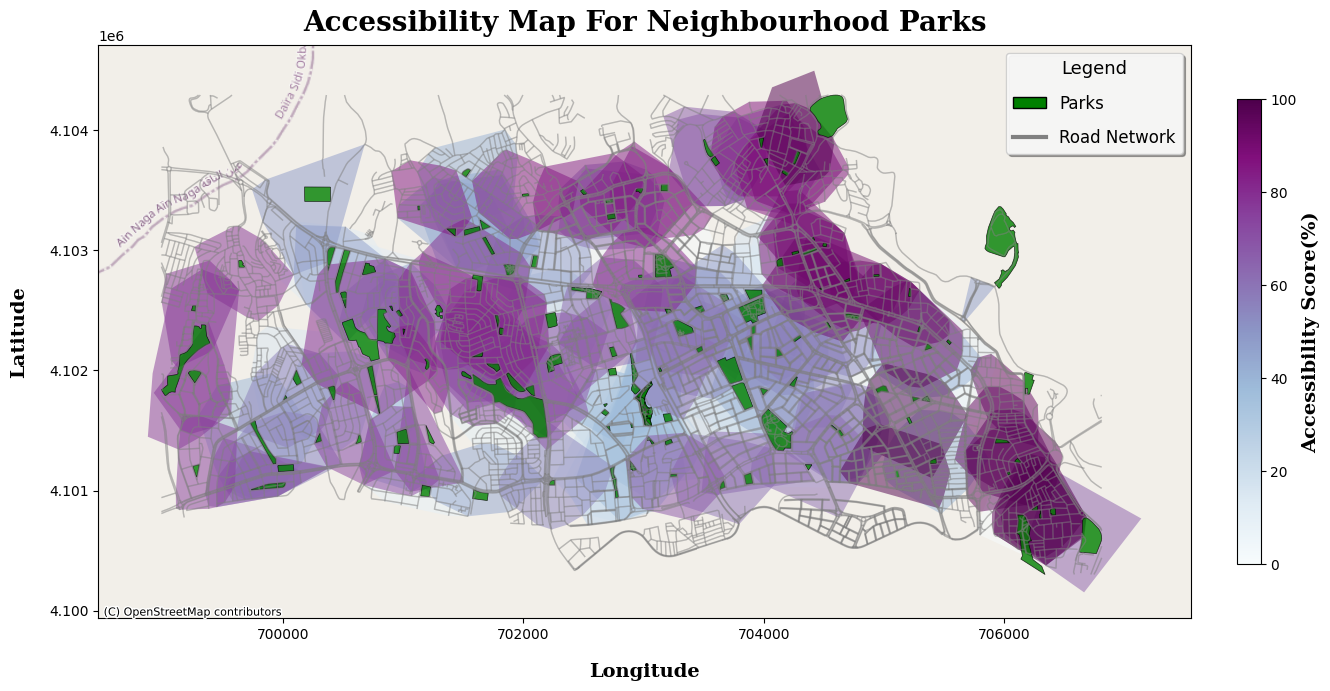

In [31]:
# Add pdi to parks DataFrame
parks = parks.join(neighborhood_comparison.set_index('park_index')[['pdi_normalized']], rsuffix='_percent')

fig, ax = plt.subplots(figsize=(15, 15))

# Plot the network buffers based on pdi_normalized
norm = mcolors.Normalize(vmin=parks['pdi_normalized'].min(), vmax=parks['pdi_normalized'].max())
cmap = plt.cm.BuPu
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

parks["network_buffer"].plot(ax=ax, cmap=cmap, linewidth=0.5, alpha=0.5)
parks.plot(ax=ax, color='green', edgecolor='black', linewidth=0.5, alpha=0.8, label='Parks')
edges_sa.plot(ax=ax, linewidth=1, edgecolor='gray', alpha=0.3, label='Road Network')

# Add basemap for context
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)
ax.set_title('Accessibility Map For Neighbourhood Parks', fontsize=20, fontweight='bold', fontfamily='serif', pad=10)
ax.set_xlabel('Longitude', fontsize=14, fontweight='bold', fontfamily='serif', labelpad=15)
ax.set_ylabel('Latitude', fontsize=14, fontweight='bold', fontfamily='serif', labelpad=15)

# Manually create the legend
legend_elements = [
    Patch(facecolor='green', edgecolor='black', label='Parks'),
    plt.Line2D([0], [0], color='gray', lw=3, label='Road Network')]

ax.legend(handles=legend_elements, loc='upper right', fontsize=12, title='Legend', title_fontsize='13', 
          frameon=True, framealpha=0.9, fancybox=True, shadow=True, labelspacing=1)

cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.02, pad=0.04)
cbar.set_label('Accessibility Score(%)', fontsize=14, fontweight='bold', fontfamily='serif')

plt.show()

----------------------

### Step 7: Propose New Park Locations

In [36]:
parks

,osm_id,code,fclass,name,Shape_Leng,Shape_Area,geometry,euclidean_buffer,network_buffer,restricted_service_area,pdi_normalized
0,174082441,7202,park,None,0.012076,3.824450e-06,"POLYGON ((706316.288 4100369.1, 706342.769 410...","POLYGON ((705629.247 4100506.567, 705618.133 4...","POLYGON ((706243.938 4100424.704, 706210.844 4...","POLYGON ((706243.938 4100424.704, 706210.844 4...",2.638230
1,180369130,7202,park,Cumhuriyet Parkı,0.006340,2.305100e-06,"POLYGON ((703233.061 4102782.307, 703183.891 4...","POLYGON ((703138.899 4102276.718, 703089.979 4...","POLYGON ((703452.119 4102466.166, 703243.847 4...","POLYGON ((703452.119 4102466.166, 703243.847 4...",3.019386
2,180369288,7202,park,Mehmet Akif Ersoy Parkı,0.003113,5.987593e-07,"POLYGON ((701882.555 4102793.894, 701875.079 4...","POLYGON ((701365.292 4102711.251, 701350.935 4...","POLYGON ((701958.722 4102368.836, 701709.356 4...","POLYGON ((701958.722 4102368.836, 701709.356 4...",3.704156
3,182657222,7202,park,None,0.003207,4.664903e-07,"POLYGON ((702947.96 4101949.283, 702918.445 41...","POLYGON ((703381.585 4101700.347, 703352.07 41...","POLYGON ((702916.42 4101763.463, 702913.988 41...","POLYGON ((702916.42 4101763.463, 702913.988 41...",6.698202
4,182657225,7202,park,None,0.002408,3.816098e-07,"POLYGON ((702954.144 4101819.546, 702935.38 41...","POLYGON ((703284.736 4101444.435, 703265.972 4...","POLYGON ((703025.642 4101539.544, 702877.349 4...","POLYGON ((703025.642 4101539.544, 702877.349 4...",12.121999
...,...,...,...,...,...,...,...,...,...,...,...
150,1303370488,7202,park,Şehit P. Er Tugay Elve Çocuk Parkı,0.001850,2.077545e-07,"POLYGON ((706428.111 4100849.836, 706432.164 4...","POLYGON ((706026.46 4100461.398, 705994.901 41...","POLYGON ((706002.327 4100644.85, 705972.294 41...","POLYGON ((706002.327 4100644.85, 705972.294 41...",2.392446
151,1303370489,7202,park,Beyazevler Mahallesi 2 Nolu Çocuk Parkı,0.001427,8.946384e-08,"POLYGON ((706283.005 4100839.523, 706236.542 4...","POLYGON ((706782.552 4100860.802, 706782.228 4...","POLYGON ((706188.325 4100481.212, 706183.135 4...","POLYGON ((706188.325 4100481.212, 706183.135 4...",2.373614
152,1303370582,7202,park,Çobandede Parkı,0.010831,7.315143e-06,"POLYGON ((704544.461 4103942.346, 704535.641 4...","POLYGON ((703941.509 4103941.383, 703939.815 4...","POLYGON ((703937.643 4103984.476, 704070.369 4...","POLYGON ((703937.643 4103984.476, 704070.369 4...",0.000000
153,1306305081,7202,park,Çınarlı Parkı,0.001646,1.567183e-07,"POLYGON ((705131.238 4101111.851, 705103.863 4...","POLYGON ((705628.474 4101164.35, 705631.23 410...","POLYGON ((704708.706 4101062.887, 704635.932 4...","POLYGON ((704708.706 4101062.887, 704635.932 4...",4.554350


----------------------

In [38]:
def propose_new_parks(parks, population_points):
    underserved = parks[parks["pdi_normalized"] < 5]
    proposed_parks = []
    for _, row in underserved.iterrows():
        centroid = row["geometry"].centroid
        proposed_parks.append(centroid.buffer(250))
    return gpd.GeoSeries(proposed_parks, crs="EPSG:32636")
    
proposed_parks = propose_new_parks(parks, population_points)
proposed_parks

0     POLYGON ((706439.899 4100562.973, 706438.695 4...
1     POLYGON ((703410.793 4102865.658, 703409.589 4...
2     POLYGON ((702135.735 4102842.036, 702134.531 4...
3     POLYGON ((702796.647 4102648.51, 702795.444 41...
4     POLYGON ((705510.679 4101762.84, 705509.475 41...
                            ...                        
64    POLYGON ((706660.437 4100823.299, 706659.233 4...
65    POLYGON ((706514.393 4100850.345, 706513.19 41...
66    POLYGON ((704801.108 4104131.8, 704799.904 410...
67    POLYGON ((705362.18 4101137.263, 705360.976 41...
68    POLYGON ((705463.733 4101583.907, 705462.53 41...
Length: 69, dtype: geometry

----------------------

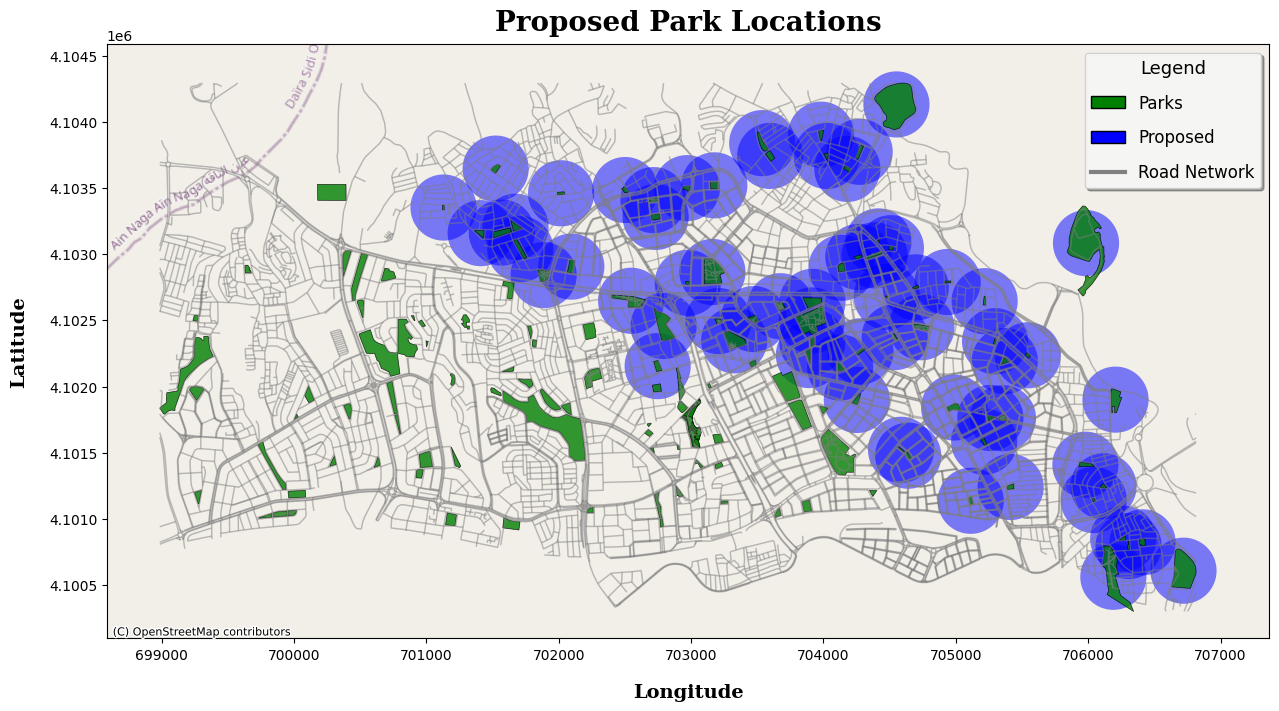

In [39]:
# Create Figure (Proposed Park Locations)
fig, ax = plt.subplots(figsize=(15, 15))
proposed_parks.plot(ax=ax, color="blue", alpha=0.5, label="Proposed Parks")
parks.plot(ax=ax, color='green', edgecolor='black', linewidth=0.5, alpha=0.8, label='Parks')
edges_sa.plot(ax=ax, linewidth=1, edgecolor='gray', alpha=0.3, label='Road Network')

# Add basemap for context
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)
ax.set_title('Proposed Park Locations', fontsize=20, fontweight='bold', fontfamily='serif', pad=10)
ax.set_xlabel('Longitude', fontsize=14, fontweight='bold', fontfamily='serif', labelpad=15)
ax.set_ylabel('Latitude', fontsize=14, fontweight='bold', fontfamily='serif', labelpad=15)

# Manually create the legend
legend_elements = [
    Patch(facecolor='green', edgecolor='black', label='Parks'),
    Patch(facecolor='blue', edgecolor='black', label='Proposed'),
    plt.Line2D([0], [0], color='gray', lw=3, label='Road Network')]

ax.legend(handles=legend_elements, loc='upper right', fontsize=12, title='Legend', title_fontsize='13', 
          frameon=True, framealpha=0.9, fancybox=True, shadow=True, labelspacing=1)

plt.show()
#plt.savefig("figure5.png")

# END ^^